In [1]:
import sys
from pathlib import Path

print(sys.executable)
print(Path.cwd())

C:\Users\catar\Documents\Ironhack\Week_7\ml_project\.venv\Scripts\python.exe
C:\Users\catar\Documents\Ironhack\Week_7\ml_project\notebooks


In [2]:
from pathlib import Path

print(Path.cwd())

C:\Users\catar\Documents\Ironhack\Week_7\ml_project\notebooks


In [3]:
import yaml

with open("../config.yaml", "r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/diabetes_binary_health_indicators_BRFSS2015.csv")
df = df.astype(int)

In [5]:
df.shape

(253680, 22)

In [6]:
df.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,1,1,1,40,1,0,0,0,0,...,1,0,5,18,15,1,0,9,4,3
1,0,0,0,0,25,1,0,0,1,0,...,0,1,3,0,0,0,0,7,6,1
2,0,1,1,1,28,0,0,0,0,1,...,1,1,5,30,30,1,0,9,4,8
3,0,1,0,1,27,0,0,0,1,1,...,1,0,2,0,0,0,0,11,3,6
4,0,1,1,1,24,0,0,0,1,1,...,1,0,2,3,0,0,0,11,5,4


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   Diabetes_binary       253680 non-null  int64
 1   HighBP                253680 non-null  int64
 2   HighChol              253680 non-null  int64
 3   CholCheck             253680 non-null  int64
 4   BMI                   253680 non-null  int64
 5   Smoker                253680 non-null  int64
 6   Stroke                253680 non-null  int64
 7   HeartDiseaseorAttack  253680 non-null  int64
 8   PhysActivity          253680 non-null  int64
 9   Fruits                253680 non-null  int64
 10  Veggies               253680 non-null  int64
 11  HvyAlcoholConsump     253680 non-null  int64
 12  AnyHealthcare         253680 non-null  int64
 13  NoDocbcCost           253680 non-null  int64
 14  GenHlth               253680 non-null  int64
 15  MentHlth              253680 non-null  int64


In [8]:
df.duplicated().sum()

np.int64(24206)

In [9]:
df.isna().sum()

Diabetes_binary         0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64

# **Description of df_lifestyle**

**Diabetes_binary** - Target/Binary - 0 = no diabetes 1 = prediabetes or diabetes

**BMI** - Feature/Integer - Body Mass Index

**Smoker** - Feature/Binary - Have you smoked at least 100 cigarettes in your entire life? (Note: 5 packs = 100 cigarettes) 0 = no 1 = yes

**PhysActivity** - Feature/Binary - physical activity in past 30 days (not including job) 0 = no 1 = yes

**Fruits** - Feature/Binary - Consume Fruit 1 or more times per day 0 = no 1 = yes

**Veggies** - Feature/Binary - Consume Vegetables 1 or more times per day 0 = no 1 = yes

**HvyAlcoholConsump** - Feature/Binary - Heavy drinkers (adult men having more than 14 drinks per week and adult women having more than 7 drinks per week) 0 = no 1 = yes

# **HYPOTHESIS**

Among people with a high BMI, do those with healthy habits have a lower diabetes rate than those without them?

Do eating fruit and vegetables daily and exercising still make a difference when weight is already a risk factor?

We're comparing people with the same weight-related risk, so BMI no longer "hides" the effect of the habits.

Lifestyle: Fruits and Veggies only tell you whether a person eats fruit/vegetables at least once a day. They don't tell you whether someone "eats healthily" overall.

In [10]:
lifestyle = ["Smoker", "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump"]

df_lifestyle = df[lifestyle + ["BMI", "Diabetes_binary"]].copy()
df_lifestyle.head()

,Smoker,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,BMI,Diabetes_binary
0,1,0,0,1,0,40,0
1,1,1,0,0,0,25,0
2,0,0,1,0,0,28,0
3,0,1,1,1,0,27,0
4,0,1,1,1,0,24,0


In [11]:
# df_lifestyle.describe()

In [12]:
df_lifestyle.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   Smoker             253680 non-null  int64
 1   PhysActivity       253680 non-null  int64
 2   Fruits             253680 non-null  int64
 3   Veggies            253680 non-null  int64
 4   HvyAlcoholConsump  253680 non-null  int64
 5   BMI                253680 non-null  int64
 6   Diabetes_binary    253680 non-null  int64
dtypes: int64(7)
memory usage: 13.5 MB


In [13]:
df_lifestyle.duplicated().sum()

np.int64(251085)

In [14]:
# How many people have (pre)diabetes? (the target)
target_count = df_lifestyle["Diabetes_binary"].value_counts()
target_pct = (df_lifestyle["Diabetes_binary"].value_counts(normalize=True) * 100).round(1)

pd.DataFrame({"People": target_count, "%": target_pct}).rename(
    index={0: "No diabetes (0)", 1: "(Pre)diabetes (1)"}
)

,People,%
Diabetes_binary,,
No diabetes (0),218334,86.1
(Pre)diabetes (1),35346,13.9


In [15]:
# How many people per habit (each group)
habits_count = df_lifestyle[lifestyle].apply(pd.Series.value_counts).T
habits_count.columns = ["No (0)", "Yes (1)"]
habits_count

,No (0),Yes (1)
Smoker,141257,112423
PhysActivity,61760,191920
Fruits,92782,160898
Veggies,47839,205841
HvyAlcoholConsump,239424,14256


In [16]:
# df_lifestyle[lifestyle].apply(lambda s: s.value_counts(normalize=True)).T.round(3)

In [17]:
habits_pct = (df_lifestyle[lifestyle]
              .apply(lambda s: s.value_counts(normalize=True))
              .T * 100).round(1)
habits_pct.columns = ["No (0) %", "Yes (1) %"]
habits_pct

,No (0) %,Yes (1) %
Smoker,55.7,44.3
PhysActivity,24.3,75.7
Fruits,36.6,63.4
Veggies,18.9,81.1
HvyAlcoholConsump,94.4,5.6


In [18]:
# Number of people per habit and diabetes status

for col in lifestyle:
    print(pd.crosstab(df_lifestyle[col], df_lifestyle["Diabetes_binary"]), "\n")

Diabetes_binary       0      1
Smoker                        
0                124228  17029
1                 94106  18317 

Diabetes_binary       0      1
PhysActivity                  
0                 48701  13059
1                169633  22287 

Diabetes_binary       0      1
Fruits                        
0                 78129  14653
1                140205  20693 

Diabetes_binary       0      1
Veggies                       
0                 39229   8610
1                179105  26736 

Diabetes_binary         0      1
HvyAlcoholConsump               
0                  204910  34514
1                   13424    832 



Don't exercise (0): 61,760 people in total
- 48,701 have no diabetes
- 13,059 have (pre)diabetes, which is 21.1%

Exercise (1): 191,920 people in total
- 169,633 have no diabetes
- 22,287 have (pre)diabetes, which is 11.6%

In [19]:
# Diabetes rate by habit: share of people with (pre)diabetes in each group

for col in lifestyle:
    print(df_lifestyle.groupby(col)["Diabetes_binary"].mean().round(3), "\n")

Smoker
0    0.121
1    0.163
Name: Diabetes_binary, dtype: float64 

PhysActivity
0    0.211
1    0.116
Name: Diabetes_binary, dtype: float64 

Fruits
0    0.158
1    0.129
Name: Diabetes_binary, dtype: float64 

Veggies
0    0.18
1    0.13
Name: Diabetes_binary, dtype: float64 

HvyAlcoholConsump
0    0.144
1    0.058
Name: Diabetes_binary, dtype: float64 



In [20]:
# PhysActivity
# 0 → 0.211: among people who don't exercise, 21.1% have (pre)diabetes
# 1 → 0.116: among people who do exercise, 11.6% have (pre)diabetes

# Inactive people have almost twice the (pre)diabetes rate of active people.

In [21]:
# BMI is a simple index of weight-to-height commonly used to classify underweight, overweight and obesity in adults. It is defined as the weight in kilograms divided by the square of the height in meters (kg/m2). For example, an adult who weighs 58 kg and whose height is 1.70 m will have a BMI of 20.1: BMI = 58 kg/(1.70 m ´ 1.70 m) = 20.1

# BMI < 17.0 indicates moderate and severe thinness
# BMI < 18.5 indicates underweight
# BMI 18.5–24.9 indicates normal weight
# BMI ≥ 25.0 indicates overweight
# BMI ≥ 30.0 indicates obesity

In [22]:
# Of the people in this group, how many have (pre)diabetes?
obese = df_lifestyle[df_lifestyle["BMI"] >= 30]

for col in ["Fruits", "Veggies", "PhysActivity"]:
    print(obese.groupby(col)["Diabetes_binary"].mean().round(3), "\n")

Fruits
0    0.244
1    0.227
Name: Diabetes_binary, dtype: float64 

Veggies
0    0.264
1    0.226
Name: Diabetes_binary, dtype: float64 

PhysActivity
0    0.299
1    0.203
Name: Diabetes_binary, dtype: float64 



In [23]:
# This output shows the percentage of people with (pre)diabetes among those with BMI ≥ 30 (obesity), split by each habit.
# 0 means "doesn't have the habit" and 1 means "has the habit"

# **Conclusions**

Lifestyle habits vs (pre)diabetes

**Distribution of habits**
- Most respondents eat vegetables daily (81%), are physically active (76%) and eat fruit daily (63%). 44% have smoked at least 100 cigarettes, and only 5.6% are heavy drinkers.
- Heavy drinkers are a small group (14,256 people), so results for this feature are less stable.

**(Pre)diabetes rate by habit (all respondents)**
- Physical activity shows the strongest association: inactive people have almost twice the (pre)diabetes rate of active people.
- Eating vegetables and fruit daily and not smoking are associated with lower rates, but the gaps are smaller.
- Heavy alcohol consumption shows an unexpected result: heavy drinkers have a lower rate (5.8% vs 14.4%). This is very likely not a protective effect. Possible explanations are reverse causation (people diagnosed with diabetes are advised to stop drinking), the small size of the group, and self-reporting bias. It's a clear example of why these results show association, not causation.

**Hypothesis: do habits still matter when BMI ≥ 30?**
- People with obesity have a much higher (pre)diabetes rate overall.
- Physical activity keeps the same gap. This is an association, not proof that exercise prevents diabetes. This supports the hypothesis: being active is associated with lower (pre)diabetes regardless of weight. (All respondents: 21.1% vs 11.6%, a gap of 9.5 points. BMI ≥ 30: 29.9% vs 20.3%, a gap of 9.6 points)
- The gaps for fruit and vegetables shrink within the obesity group. Part of their association in the full population is probably explained by BMI.

**Conclusion: the hypothesis is supported for physical activity, and only weakly for fruit and vegetable intake.**

Smoker: [np.int64(0), np.int64(1)]
PhysActivity: [np.int64(0), np.int64(1)]
Fruits: [np.int64(0), np.int64(1)]
Veggies: [np.int64(0), np.int64(1)]
HvyAlcoholConsump: [np.int64(0), np.int64(1)]
Diabetes_binary: [np.int64(0), np.int64(1)]
count    253680.0
mean         28.4
std           6.6
min          12.0
25%          24.0
50%          27.0
75%          31.0
max          98.0
Name: BMI, dtype: float64


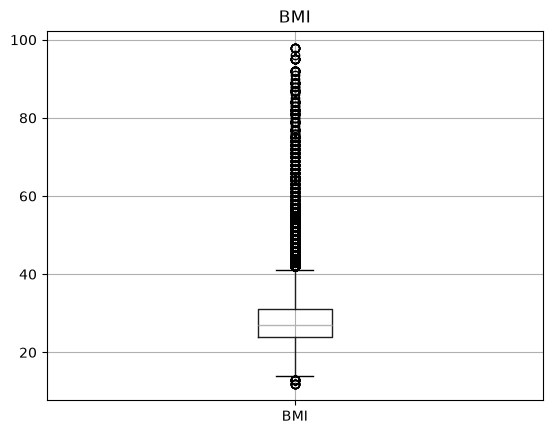

BMI upper limit (IQR): 41.5
Rows above it: 9820 (3.9%)
Rows with BMI > 60: 805


In [24]:
# Verification of Outliers in the BMI

lifestyle = ["Smoker", "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump"]
df_lifestyle = df[lifestyle + ["BMI", "Diabetes_binary"]].copy()

# Value ranges: lifestyle + target must be 0/1
for col in lifestyle + ["Diabetes_binary"]:
    print(f"{col}: {sorted(df_lifestyle[col].unique())}")

# BMI outliers
print(df_lifestyle["BMI"].describe().round(1))

df_lifestyle.boxplot(column="BMI")
plt.title("BMI")
plt.show()

q1, q3 = df_lifestyle["BMI"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"BMI upper limit (IQR): {upper:.1f}")
print(f"Rows above it: {(df_lifestyle['BMI'] > upper).sum()} ({(df_lifestyle['BMI'] > upper).mean():.1%})")
print(f"Rows with BMI > 60: {(df_lifestyle['BMI'] > 60).sum()}")

**Conclusion: BMI outliers**
- BMI ranges from 12 to 98, with a median of 27 and most values between 24 and 31 (IQR).
- The IQR rule flags 9,820 rows (3.9%) above 41.5, and 805 rows have a BMI above 60.
- We don't remove values above 41.5. A BMI above 40 corresponds to severe obesity, which is real and clinically relevant, and this is exactly the highest-risk group for diabetes. Removing it would remove important information.
- Extreme values (e.g. BMI 98, or 12 at the low end) are very rare and may be reporting errors.

In [25]:
import numpy as np
from scipy.stats import chi2_contingency

# Chi-square test for each habit, among people with obesity (BMI >= 30)
obese = df_lifestyle[df_lifestyle["BMI"] >= 30]

test_rows = []
for col in ["PhysActivity", "Veggies", "Fruits", "Smoker", "HvyAlcoholConsump"]:
    table = pd.crosstab(obese[col], obese["Diabetes_binary"])
    chi2, p_value, _, _ = chi2_contingency(table)
    rates = obese.groupby(col)["Diabetes_binary"].mean() * 100
    cramers_v = np.sqrt(chi2 / table.values.sum())   # effect size for a 2x2 table (0 = none, 1 = perfect)
    test_rows.append({
        "Habit": col,
        "Rate without (0) %": rates[0],
        "Rate with (1) %": rates[1],
        "Gap (pts)": rates[1] - rates[0],
        "Chi2": chi2,
        "p-value": p_value,
        "Cramér's V": cramers_v,
        "Reject H0?": p_value < 0.05,
    })

pd.DataFrame(test_rows).set_index("Habit").round(4)

,Rate without (0) %,Rate with (1) %,Gap (pts),Chi2,p-value,Cramér's V,Reject H0?
Habit,,,,,,,
PhysActivity,29.9375,20.2899,-9.6476,995.9562,0.0,0.1065,True
Veggies,26.3969,22.5534,-3.8434,124.1163,0.0,0.0376,True
Fruits,24.4306,22.6539,-1.7768,37.5888,0.0,0.0207,True
Smoker,20.8887,26.4003,5.5117,368.9900,0.0,0.0648,True
HvyAlcoholConsump,23.9092,11.9347,-11.9745,285.5640,0.0,0.0570,True


The main hypothesis covers physical activity, fruit and vegetable intake. Smoking and heavy alcohol consumption are tested as secondary, exploratory checks.
Note: for Smoker and HvyAlcoholConsump, "1" means the unhealthy habit, so a positive gap is expected for smoking. A negative gap for alcohol should not be read as protective (possible reverse causation and self-reporting bias).

We reject H0 for all five habits, but this is expected with ~60,000 people. The effect sizes are small: physical activity has the largest association, while fruit and vegetables are statistically significant but practically negligible.

In [26]:
# Can habits + BMI predict (pre)diabetes? / Do habits still matter when BMI is high?

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42
TARGET = "Diabetes_binary"

# Lifestyle model: the 5 habits + BMI
X = df_lifestyle.drop(columns=TARGET)
y = df_lifestyle[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

In [28]:
results = []   # reset every time this cell runs, to avoid duplicate rows

def evaluate_classifier(name, fitted_pipeline):
    """Record train and test metrics; the positive class (1) = (pre)diabetes."""
    pred_train = fitted_pipeline.predict(X_train)
    pred_test = fitted_pipeline.predict(X_test)
    scores = {
        "Model": name,
        "Train recall": recall_score(y_train, pred_train),
        "Test recall": recall_score(y_test, pred_test),
        "Test precision": precision_score(y_test, pred_test, zero_division=0),
        "Test F1": f1_score(y_test, pred_test),
        "Test accuracy": accuracy_score(y_test, pred_test),
    }
    results.append(scores)
    return pd.Series(scores)

In [29]:
# Baseline: always predicts "no diabetes" (the majority class)
baseline = Pipeline([("model", DummyClassifier(strategy="most_frequent"))])
baseline.fit(X_train, y_train)
evaluate_classifier("Baseline (always 0)", baseline)

Model             Baseline (always 0)
Train recall                      0.0
Test recall                       0.0
Test precision                    0.0
Test F1                           0.0
Test accuracy                0.860671
dtype: object

In [30]:
models = {
    "KNN": Pipeline([("scaler", StandardScaler()),
                     ("model", KNeighborsClassifier(n_neighbors=15))]),
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                     ("model", LogisticRegression(max_iter=1000, class_weight="balanced",
                                                  random_state=RANDOM_STATE))]),
    "Decision Tree": Pipeline([("model", DecisionTreeClassifier(max_depth=6, class_weight="balanced",
                                                  random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([("model", RandomForestClassifier(n_estimators=100, max_depth=8,
                                                  class_weight="balanced", n_jobs=-1,
                                                  random_state=RANDOM_STATE))]),
}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    evaluate_classifier(name, pipe)

In [31]:
# Gradient Boosting has no class_weight option, so we balance it with sample weights
gb = Pipeline([("model", GradientBoostingClassifier(n_estimators=100, max_depth=3,
                learning_rate=0.1, random_state=RANDOM_STATE))])
gb.fit(X_train, y_train, model__sample_weight=compute_sample_weight("balanced", y_train))
evaluate_classifier("Gradient Boosting (balanced)", gb)
models["Gradient Boosting (balanced)"] = gb

In [32]:
comparison = pd.DataFrame(results).set_index("Model")
comparison.sort_values("Test recall", ascending=False).round(3)

,Train recall,Test recall,Test precision,Test F1,Test accuracy
Model,,,,,
Gradient Boosting (balanced),0.672,0.670,0.229,0.341,0.639
Decision Tree,0.667,0.660,0.226,0.337,0.638
Random Forest,0.667,0.655,0.229,0.339,0.644
Logistic Regression,0.606,0.602,0.239,0.342,0.677
KNN,0.049,0.044,0.335,0.078,0.855
Baseline (always 0),0.000,0.000,0.000,0.000,0.861


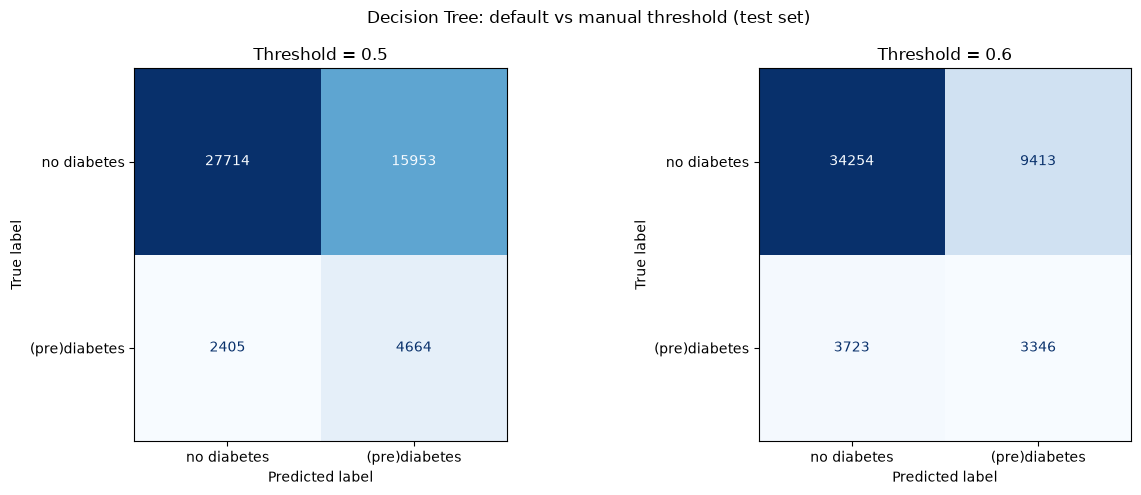

,Recall,Precision,False positives,Missed cases
Threshold,,,,
0.5,0.660,0.226,15953,2405
0.6,0.473,0.262,9413,3723


In [33]:
# Selected model: Decision Tree, with performance similar to Random Forest but simpler and easier to explain
best = models["Decision Tree"]

# Compare the default threshold (0.5) with a stricter one (0.6)# The tree is balanced, so its probabilities are pushed up; raising the threshold above 0.5
# means we only flag people the model is more confident about → fewer unnecessary tests.
threshold = 0.60

proba_test = best.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
summary = []

for ax, t in zip(axes, [0.5, threshold]):
    pred = (proba_test >= t).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False, cmap="Blues",
                                            display_labels=["no diabetes", "(pre)diabetes"])
    ax.set_title(f"Threshold = {t}")
    summary.append({
        "Threshold": t,
        "Recall": recall_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "False positives": int(((pred == 1) & (y_test == 0)).sum()),
        "Missed cases": int(((pred == 0) & (y_test == 1)).sum()),
    })

plt.suptitle("Decision Tree: default vs manual threshold (test set)")
plt.tight_layout()
plt.show()

pd.DataFrame(summary).set_index("Threshold").round(3)

Threshold 0.5:
- Of the 7,069 people with (pre)diabetes, the model finds 4,664 (66%).
- It misses 2,405 (34%), about 1 in 3.

Threshold 0.6:
- It finds 3,346 (47%).
- It misses 3,723 (53%), more than half.

Raising the threshold from 0.5 to 0.6 reduces false positives by 41% (15,953 - 9,413) but misses 1,318 more people with (pre)diabetes, and recall falls from 0.66 to 0.47. Since the goal is screening, where a missed case costs more than an extra test, we keep the default threshold (0.5). A higher threshold would only make sense if testing capacity were limited.

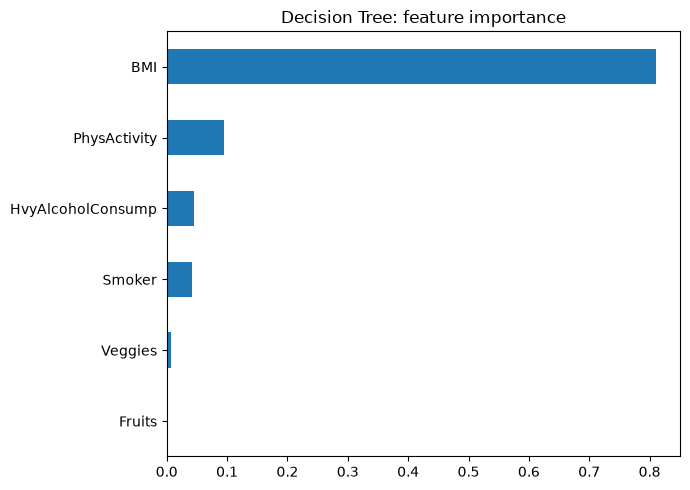

In [34]:
importances = pd.Series(best.named_steps["model"].feature_importances_,
                        index=X_train.columns).sort_values()
importances.plot.barh(figsize=(7, 5), title="Decision Tree: feature importance")
plt.tight_layout()
plt.show()

In [35]:
# Same model, different feature sets: tests whether habits add predictive power beyond BMI
feature_sets = {
    "BMI only": ["BMI"],
    "Lifestyle only": lifestyle,
    "Lifestyle + BMI": lifestyle + ["BMI"],
}

for name, cols in feature_sets.items():
    pipe = Pipeline([("model", DecisionTreeClassifier(max_depth=6, class_weight="balanced",
                     random_state=RANDOM_STATE))])
    pipe.fit(X_train[cols], y_train)
    pred = pipe.predict(X_test[cols])
    print(f"{name}: recall={recall_score(y_test, pred):.3f}, F1={f1_score(y_test, pred):.3f}")

BMI only: recall=0.628, F1=0.322
Lifestyle only: recall=0.502, F1=0.283
Lifestyle + BMI: recall=0.660, F1=0.337


**Model comparison**

- BMI dominates the model (importance ~0.81), followed by physical activity (~0.09). Fruit and vegetables contribute almost nothing.
- Recall by feature set: BMI only 0.628 - Lifestyle only 0.502 - Lifestyle + BMI 0.660.
- Habits alone find half of the cases, and adding them to BMI improves recall by about 3 points. The extra signal comes almost entirely from physical activity.
- This is consistent with the chi-square results: physical activity matters even when weight is accounted for; fruit and vegetables add little.

# **Final conclusion**

- Among people with obesity, being physically active is associated with a ~10-point lower (pre)diabetes rate (29.9% vs 20.3%). This is the clearest lifestyle signal.
- Fruit and vegetable intake (as measured here: at least once a day) has very little effect.
- For the app: BMI plus one physical-activity question already flags 2 in 3 people with (pre)diabetes. Short onboarding questions are enough for a first screening.
- Recommendation to users: physical activity is the habit most worth encouraging, especially for people with a high BMI.
- Limitations: survey data (self-reported), cross-sectional (association, not causation), binary habit questions.